In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/city_day_clean.csv", parse_dates=["Date"])

print(df.shape)
df.dtypes

(29531, 19)


City                        str
Date             datetime64[us]
PM2.5                   float64
PM10                    float64
NO                      float64
NO2                     float64
NOx                     float64
NH3                     float64
CO                      float64
SO2                     float64
O3                      float64
Benzene                 float64
Toluene                 float64
AQI                     float64
AQI_Bucket                  str
Year                      int64
Month                     int64
Season                      str
AQI_Above_500              bool
dtype: object

Year
2015    69.3
2016    82.3
2017    80.0
2018    59.2
2019    50.9
2020    31.5
Name: PM2.5, dtype: float64


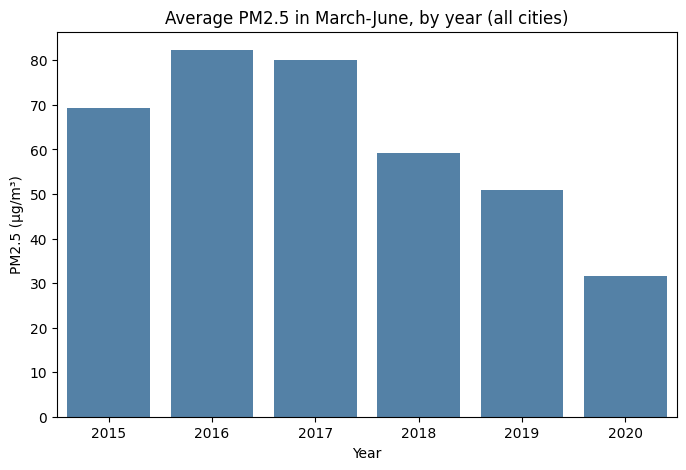

In [2]:
# Keep only March to June (the lockdown months in 2020)
spring = df[df["Month"].isin([3, 4, 5, 6])]

# Average PM2.5 for each year
yearly_pm25 = spring.groupby("Year")["PM2.5"].mean().round(1)
print(yearly_pm25)

# Bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x=yearly_pm25.index, y=yearly_pm25.values, color="steelblue")
plt.title("Average PM2.5 in March-June, by year (all cities)")
plt.xlabel("Year")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

In [3]:
# Which cities have PM2.5 data in each year?
cities_per_year = (
    df[df["PM2.5"].notnull()]
    .groupby("Year")["City"]
    .nunique()
)
print(cities_per_year)

# Keep only cities with PM2.5 data in March-June of ALL six years
spring = df[df["Month"].isin([3, 4, 5, 6]) & df["PM2.5"].notnull()]
years_per_city = spring.groupby("City")["Year"].nunique()
common_cities = years_per_city[years_per_city == 6].index.tolist()
print("Cities with data in all 6 years:", common_cities)

# Redo the average using only those cities
fair = spring[spring["City"].isin(common_cities)]
fair_yearly = fair.groupby("Year")["PM2.5"].mean().round(1)
print(fair_yearly)

Year
2015     7
2016     9
2017    14
2018    17
2019    23
2020    26
Name: City, dtype: int64
Cities with data in all 6 years: ['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Lucknow']
Year
2015    65.8
2016    68.4
2017    67.6
2018    62.9
2019    58.8
2020    37.1
Name: PM2.5, dtype: float64


## Finding 1: Did PM2.5 drop during the 2020 lockdown?

**First chart (all cities):** The average PM2.5 for March-June fell from 82.3 in 2016 to 31.5 in 2020. This looked like a steady decline followed by a lockdown drop.

**Why it was misleading:** The number of cities with PM2.5 data grew from 7 in 2015 to 26 in 2020. The average was calculated over different sets of cities each year, so part of the "decline" came from the changing city mix, not real improvement.

**Fair chart (same cities only):** Using only the cities with data in all six years, average March-June PM2.5 was 58.8 in 2019 and 37.1 in 2020. Before 2020 the decline was gentle, and in 2020 it dropped sharply.

**Conclusion:** This is consistent with a lockdown effect. However, weather and other factors were not controlled, so we cannot say the lockdown was the only cause.

City
Delhi                 259.5
Patna                 240.8
Gurugram              225.1
Lucknow               218.0
Talcher               172.9
Jorapokhar            159.3
Brajrajnagar          150.3
Kolkata               140.6
Jaipur                133.7
Amritsar              119.9
Visakhapatnam         117.3
Chennai               114.5
Hyderabad             109.2
Mumbai                105.4
Amaravati              95.3
Bengaluru              94.3
Thiruvananthapuram     75.9
Name: AQI, dtype: float64


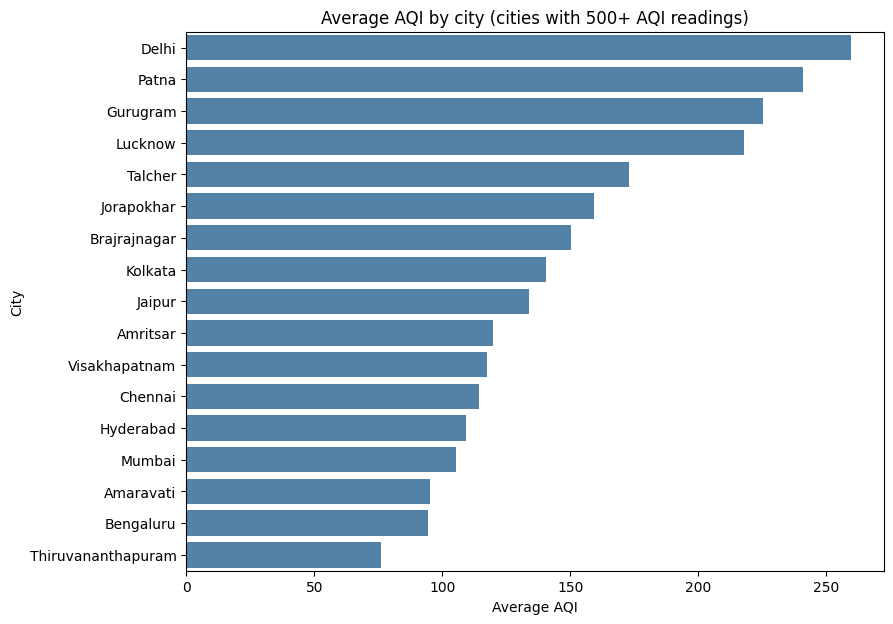

In [4]:
# Average AQI per city (only cities with enough data)
city_counts = df["AQI"].groupby(df["City"]).count()
enough_data = city_counts[city_counts >= 500].index

city_aqi = (
    df[df["City"].isin(enough_data)]
    .groupby("City")["AQI"]
    .mean()
    .round(1)
    .sort_values(ascending=False)
)
print(city_aqi)

plt.figure(figsize=(9, 7))
sns.barplot(x=city_aqi.values, y=city_aqi.index, color="steelblue")
plt.title("Average AQI by city (cities with 500+ AQI readings)")
plt.xlabel("Average AQI")
plt.ylabel("City")
plt.show()

Season
Winter          204.0
Summer          134.4
Monsoon         100.3
Post-Monsoon    191.3
Name: AQI, dtype: float64


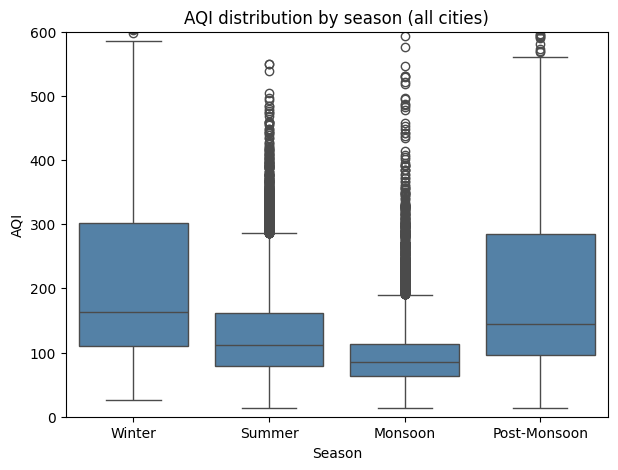

In [5]:
# Average AQI by season
season_order = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]
season_aqi = df.groupby("Season")["AQI"].mean().reindex(season_order).round(1)
print(season_aqi)

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Season", y="AQI", order=season_order, color="steelblue")
plt.title("AQI distribution by season (all cities)")
plt.xlabel("Season")
plt.ylabel("AQI")
plt.ylim(0, 600)
plt.show()

## Finding 2: Which season has the worst air?

Winter had the worst average AQI (204.0) and Monsoon had the cleanest(100.3).
Pollution is higher in winter because cold air traps pollutants near the ground and there is little wind or rain to clear them.
Winter and Post-Monsoon also had the widest spread of AQI values, which means the worst days were much worse than the typical day.

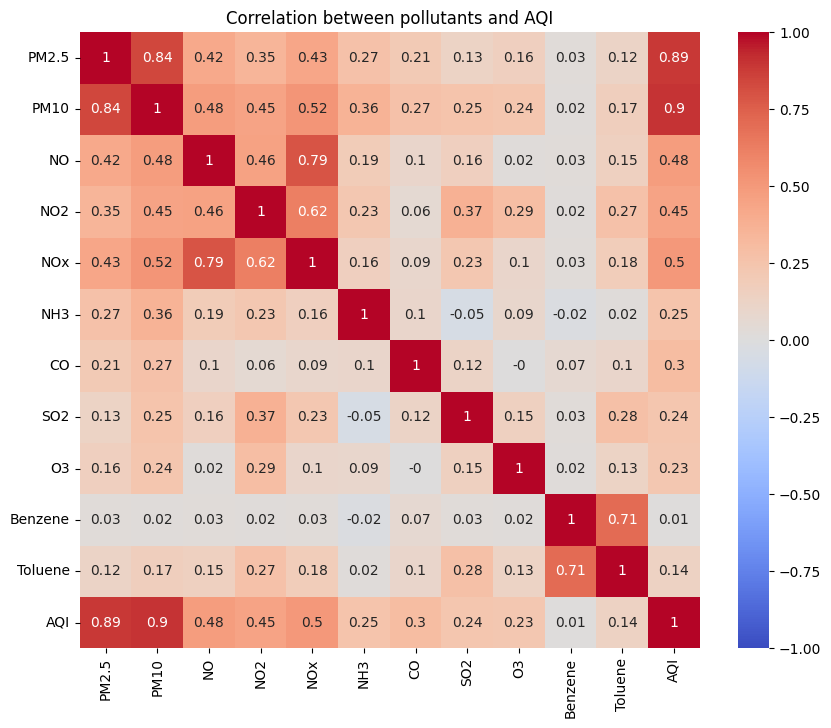

In [6]:
# Columns to compare
corr_cols = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene", "AQI"]

# Correlation matrix (pandas ignores missing values pair by pair)
corr_matrix = df[corr_cols].corr().round(2)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between pollutants and AQI")
plt.show()

## Finding 3: How do pollutants relate to AQI?

AQI correlates most strongly with PM10 (0.90) and PM2.5 (0.89).
It correlates least with Benzene (0.01).
This makes sense because AQI is calculated from the worst pollutant of the day, which in India is usually a particle (PM10 or PM2.5).

PM2.5 and PM10 are also strongly correlated with each other (0.84), so they carry similar information. NO and NOx (0.79) and Benzene and Toluene (0.71) are linked in the same way.

Note: this is correlation, not proof of cause. Also, AQI is built from the other pollutants, so a model predicting AQI from them would be partly just rediscovering the formula (data leakage).

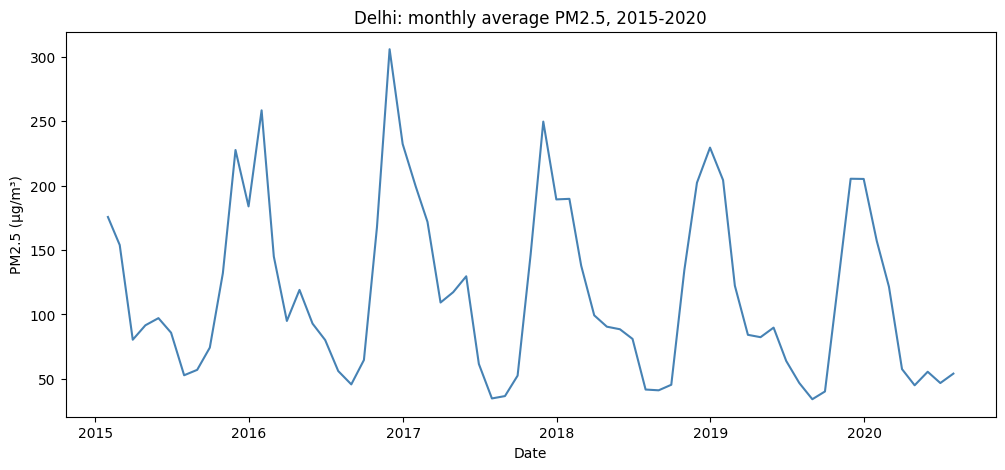

Year
2015    113.7
2016    131.9
2017    131.3
2018    114.4
2019    107.9
2020     80.5
Name: PM2.5, dtype: float64


In [8]:
# Keep only Delhi
delhi = df[df["City"] == "Delhi"]

# 1. Monthly average PM2.5 over time
delhi_monthly = delhi.set_index("Date")["PM2.5"].resample("ME").mean()

plt.figure(figsize=(12, 5))
plt.plot(delhi_monthly.index, delhi_monthly.values, color="steelblue")
plt.title("Delhi: monthly average PM2.5, 2015-2020")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

# 2. Fair yearly comparison: January-June only
delhi_jan_jun = delhi[delhi["Month"] <= 6]
delhi_yearly = delhi_jan_jun.groupby("Year")["PM2.5"].mean().round(1)
print(delhi_yearly)

## Finding 4: How has Delhi's PM2.5 changed over time?

Delhi's PM2.5 follows a yearly pattern: it peaks in winter (roughly November to January) and is lowest in the monsoon (roughly July to September).
For January-June, the average was highest in 2016 (131.9) and lowest in 2020 (80.5).
The 2020 value is about 27 lower than 2019 (107.9), which is consistent with a lockdown effect, though weather was not controlled.